# Deep Neural Networks

In [1]:
import torch
import torch.nn as nn
import torchvision.transforms as tr
import torchvision.datasets as ds
import torch.nn.functional as f
import matplotlib.pylab as plt
import numpy as np

## Neural Network Module and Training function

In [16]:
# Create the model class using sigmoid as the activation function
# define the neural network with two hidden layers

class n_net_sig(nn.Module):

    # Constructor
    def __init__(self, D_in, H1, H2 , D_out):
        super(n_net_sig, self).__init__()
        self.linear1 = nn.Linear(D_in, H1)
        self.linear2 = nn.Linear(H1, H2)
        self.linear3 = nn.Linear(H2, D_out)

    # Prediction
    def forward(self, x):
        x = torch.sigmoid(self.linear1(x))
        x = torch.sigmoid(self.linear2(x))
        x = self.linear3(x)
        return x
        

In [19]:
# Create the model class using Tanh as the activation function
# define the neural network with two hidden layers

class n_net_tanh(nn.Module):

    # Constructor
    def __init__(self, D_in, H1, H2 , D_out):
        super(n_net_tanh, self).__init__()
        self.linear1 = nn.Linear(D_in, H1)
        self.linear2 = nn.Linear(H1, H2)
        self.linear3 = nn.Linear(H2, D_out)

    # Prediction
    def forward(self, x):
        x = torch.tanh(self.linear1(x))
        x = torch.tanh(self.linear2(x))
        x = self.linear3(x)
        return x
        

In [20]:
# Create the model class using Relu as the activation function
# define the neural network with two hidden layers

class n_net_relu(nn.Module):

    # Constructor
    def __init__(self, D_in, H1, H2 , D_out):
        super(n_net_relu, self).__init__()
        self.linear1 = nn.Linear(D_in, H1)
        self.linear2 = nn.Linear(H1, H2)
        self.linear3 = nn.Linear(H2, D_out)

    # Prediction
    def forward(self, x):
        x = torch.relu(self.linear1(x))
        x = torch.relu(self.linear2(x))
        x = self.linear3(x)
        return x
        

In [9]:
# Train the model

def train(model, crt, train_loader, valid_loader, opt, epochs=100):
    i = 0
    use_dic = {'train_loss': [], 'valid_acc': []}

    for epoch in range(epochs):
        for i, (x,y) in enumerate(train_loader):
            opt.zero_grad()
            z = model(x.view(-1, 28*28))
            loss = crt(z,y)
            loss.backward()
            opt.step()
            use_dic['train_loss'].append(loss.data.item())

        correct = 0

        for x,y in valid_loader:
            z = model(x.view(-1, 28*28))
            _, label = torch.max(z, 1)
            correct += (label == y).sum().item()

        accuracy = 100 * (correct / len(valid_dataset))
        use_dic['valid_acc'].append(accuracy)

    return use_dic

## Make Some Data

In [8]:
# Create the training dataset
train_dataset = ds.MNIST(root='./data', train=True, download=True, transform=tr.ToTensor())

100.0%
100.0%
100.0%
100.0%


In [10]:
# Create the training dataset
valid_dataset = ds.MNIST(root='./data', train=False, download=True, transform=tr.ToTensor())

In [12]:
# Create the train and valid data loader
from torch.utils.data import DataLoader
train_loader = DataLoader(dataset=train_dataset, batch_size=2000, shuffle=True)
valid_loader = DataLoader(dataset=valid_dataset, batch_size=5000, shuffle=True)

## Define Neural Network, Criterion function, Optimizer and train the model

In [11]:
crt = nn.CrossEntropyLoss()

In [14]:
# Create the model with 100 hidden layers
input = 28 * 28
hidden1 = 50
hidden2 = 50
output = 10

epochs = 10

## Test Sigmoid, Tanh and Relu

In [17]:
# train the model with sigmoid function
model_sig = n_net_sig(input,hidden1,hidden2,output)
opt = torch.optim.SGD(model_sig.parameters(), lr=0.01)
train_sig = train(model_sig, crt, train_loader, valid_loader, opt,epochs=epochs)

In [21]:
# train the model with Tanh function
model_tanh = n_net_tanh(input,hidden1,hidden2,output)
opt = torch.optim.SGD(model_tanh.parameters(), lr=0.01)
train_tanh = train(model_tanh, crt, train_loader, valid_loader, opt,epochs=epochs)

In [22]:
# train the model with relu function
model_relu = n_net_relu(input,hidden1,hidden2,output)
opt = torch.optim.SGD(model_relu.parameters(), lr=0.01)
train_relu = train(model_relu, crt, train_loader, valid_loader, opt,epochs=epochs)

## Analyze Results

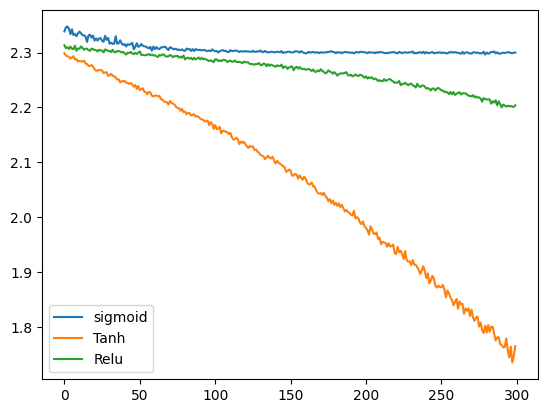

In [23]:
# Compare the training loss
plt.plot(train_sig['train_loss'], label='sigmoid')
plt.plot(train_tanh['train_loss'], label='Tanh')
plt.plot(train_relu['train_loss'], label='Relu')
plt.legend()

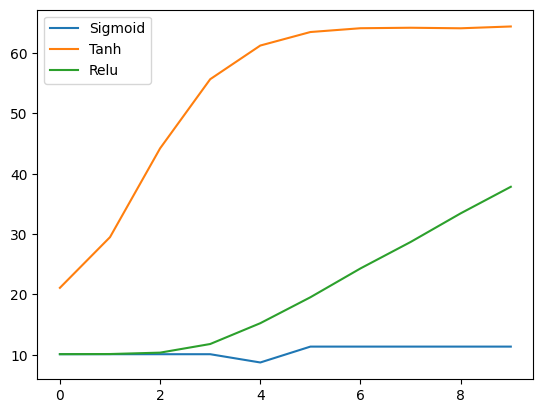

In [24]:
# Compare the validation accuracy
plt.plot(train_sig['valid_acc'], label='Sigmoid')
plt.plot(train_tanh['valid_acc'], label='Tanh')
plt.plot(train_relu['valid_acc'], label='Relu')
plt.legend()